In [1]:
from itertools import product
import pickle
from tqdm import tqdm, trange

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from corner import corner as corner_plot

from scipy import special, stats
from scipy.stats import gaussian_kde, chi2
from scipy.interpolate import interp1d, RegularGridInterpolator

import os

from local_utils import delaunaytor
from popsummary.popresult import PopulationResult
from astropy.cosmology import Planck15
from astropy import units as u
import popsummary
import plot_funcs_bbh_mass as pf


plt.style.use("tableau-colorblind10")
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.size"] = 14
plt.rcParams["text.usetex"] = True

In [2]:
def q_flat(x):
    ans=1/(5-(-15))

    return ans


def kl_divergence_kde_p_known_q(p_samples, q_pdf, base=np.e, bandwidth='scott'):
    """
    Estimate KL divergence D_KL(P || Q) where:
      - P is only known via samples (estimated with KDE)
      - Q is known analytically via q_pdf(x)
    
    Parameters:
        p_samples (array): 1D array of samples from P
        q_pdf (function): function that returns q(x) given x
        base (float): logarithm base (e.g., np.e or 2)
        bandwidth: bandwidth for KDE (default: 'scott')
    
    Returns:
        float: Estimated KL divergence D_KL(P || Q)
    """
    p_samples = np.asarray(p_samples)
    kde = gaussian_kde(p_samples, bw_method=bandwidth)

    # Evaluate both p(x) and q(x) at the sample points
    p_kde_vals = kde(p_samples)
    q_vals = q_pdf(p_samples)

    # Avoid division by zero or log(0)
    epsilon = 1e-12
    p_kde_vals = np.clip(p_kde_vals, epsilon, None)
    q_vals = np.clip(q_vals, epsilon, None)

    log_ratio = np.log(p_kde_vals / q_vals)
    kl = np.mean(log_ratio)

    return kl / np.log(base)


def kl_divergence_kde(p_samples, q_samples, base=np.e, bandwidth='scott'):
    """
    Estimate delta divergence D_delta(P || Q) where:
      - P is known via samples (estimated with KDE)
      - Q is known via samples (estimated with KDE)
    
    Parameters:
        p_samples (array): 1D array of samples from P
        q_samples (array): 1D array of samples from Q
        base (float): logarithm base (e.g., np.e or 2)
        bandwidth: bandwidth for KDE (default: 'scott')
    
    Returns:
        float: Estimated delta divergence D_delta(P || Q)
    """
    p_samples = np.asarray(p_samples)
    kde_p = gaussian_kde(p_samples, bw_method=bandwidth)

    q_samples = np.asarray(q_samples)
    kde_q = gaussian_kde(q_samples, bw_method=bandwidth)

    # Evaluate both p(x) and q(x) at the sample points
    p_kde_vals = kde_p(p_samples)
    q_kde_vals = kde_q(p_samples)

    # Avoid division by zero or log(0)
    epsilon = 1e-12
    p_kde_vals = np.clip(p_kde_vals, epsilon, None)
    q_kde_vals = np.clip(q_kde_vals, epsilon, None)

    log_ratio = np.log(p_kde_vals / q_kde_vals)
    delta = np.mean(log_ratio)

    return delta / np.log(base)

## Use LVK population analysis results as `true' population

In [3]:
gwtc5 = '/home/tristan-bruel/Documents/Science/LVK/gwtc5'
zeval = 0.2
spm_color = '#CD5C5C'
wpm_color = '#2C5AA0'

## DEFAULT PARAMETRIC MODEL ##
strong_bbh_O4b = PopulationResult(fname=f'{gwtc5}/popsummary_files/gwtc5_updated_default_mmax_mass_TwoPeakBrokenPowerLawSmoothedMassDistribution_redshift_PowerLawRedshift_magnitude_iid_spin_magnitude_gaussian_tilt_iid_spin_orientation_popsummary_result.h5')
strong_bbh_O4b_z_grid, strong_bbh_O4b_Rz = strong_bbh_O4b.get_rates_on_grids('redshift')
strong_bbh_O4b_z_grid = strong_bbh_O4b_z_grid.reshape((strong_bbh_O4b_z_grid.size, ))
strong_bbh_O4b_m1_grid, strong_bbh_O4b_Rm1 = strong_bbh_O4b.get_rates_on_grids('mass_1')
strong_bbh_O4b_m1_grid = strong_bbh_O4b_m1_grid.reshape((strong_bbh_O4b_m1_grid.size, ))
strong_bbh_O4b_q_grid, strong_bbh_O4b_Rq = strong_bbh_O4b.get_rates_on_grids('mass_ratio')
strong_bbh_O4b_q_grid = strong_bbh_O4b_q_grid.reshape((strong_bbh_O4b_q_grid.size, ))
redshift_factor_strong_bbh_o4b = (1 + zeval)**(strong_bbh_O4b.get_hyperparameter_samples(hyperparameters=['lamb']))

## PIXELPOP ##
z_pixelpop = PopulationResult(fname=f'{gwtc5}/popsummary_files/may26_datarelease/z_varcut1/z_varcut1_popsummary.h5')
pixelpop_z_grid, pixelpop_Rz = z_pixelpop.get_rates_on_grids('redshift')
pixelpop_z_grid = pixelpop_z_grid.reshape((pixelpop_z_grid.size, ))
m1m2_pixelpop = PopulationResult(fname=f'{gwtc5}/popsummary_files/may26_datarelease/m1m2_varcut1/m1m2_varcut1_popsummary.h5')
(pixelpop_m1_grid, pixelpop_m2_grid), pixelpop_R = m1m2_pixelpop.get_rates_on_grids('joint_pixelpop_rate')
pixelpop_m1_grid, pixelpop_Rm1 = m1m2_pixelpop.get_rates_on_grids('log_mass_1')
pixelpop_m1_grid = pixelpop_m1_grid.reshape((pixelpop_m1_grid.size, ))
redshift_factor_pixelpop_m1 = (1 + zeval)**(m1m2_pixelpop.get_hyperparameter_samples(hyperparameters=['lamb']))
m1q_pixelpop = PopulationResult(fname=f'{gwtc5}/popsummary_files/may26_datarelease/bbh_m1q_varcut1/bbh_m1q_varcut1_popsummary.h5')
pixelpop_q_grid, pixelpop_Rq = m1q_pixelpop.get_rates_on_grids('mass_ratio')
pixelpop_q_grid = pixelpop_q_grid.reshape((pixelpop_q_grid.size, ))
redshift_factor_pixelpop_q = (1 + zeval)**(m1q_pixelpop.get_hyperparameter_samples(hyperparameters=['lamb']))

opening existing popsummary file: /home/tristan-bruel/Documents/Science/LVK/gwtc5/popsummary_files/gwtc5_updated_default_mmax_mass_TwoPeakBrokenPowerLawSmoothedMassDistribution_redshift_PowerLawRedshift_magnitude_iid_spin_magnitude_gaussian_tilt_iid_spin_orientation_popsummary_result.h5
opening existing popsummary file: /home/tristan-bruel/Documents/Science/LVK/gwtc5/popsummary_files/may26_datarelease/z_varcut1/z_varcut1_popsummary.h5
opening existing popsummary file: /home/tristan-bruel/Documents/Science/LVK/gwtc5/popsummary_files/may26_datarelease/m1m2_varcut1/m1m2_varcut1_popsummary.h5
opening existing popsummary file: /home/tristan-bruel/Documents/Science/LVK/gwtc5/popsummary_files/may26_datarelease/bbh_m1q_varcut1/bbh_m1q_varcut1_popsummary.h5


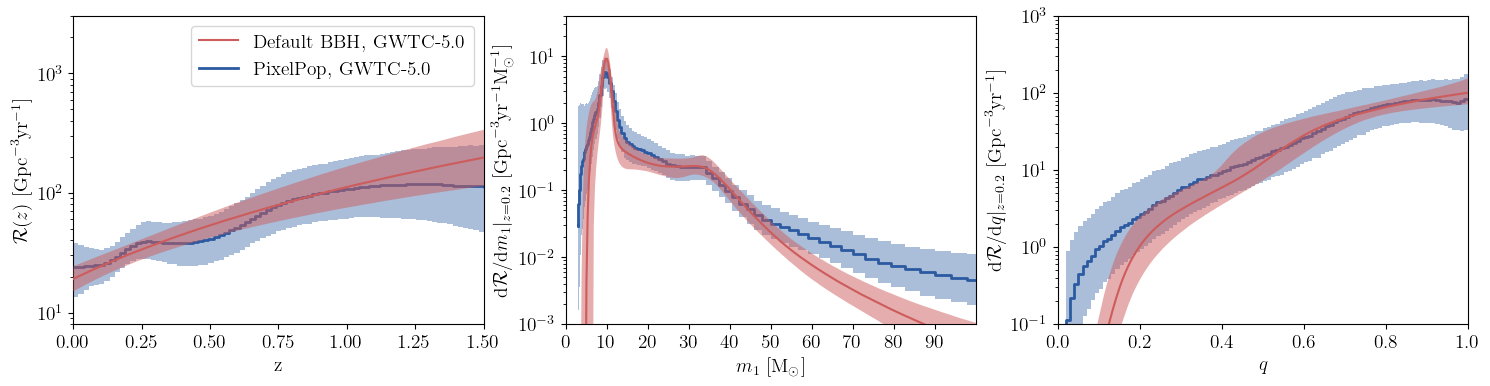

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18,4))

# Merger rate with redshift #
ax = axes[0]
ax.plot(strong_bbh_O4b_z_grid, np.quantile(strong_bbh_O4b_Rz, 0.5, axis = 0),
        color=spm_color, label='Default BBH, GWTC-5.0', lw=1.5, zorder=5)
ax.fill_between(strong_bbh_O4b_z_grid,
        np.quantile(strong_bbh_O4b_Rz, 0.05, axis=0),
        np.quantile(strong_bbh_O4b_Rz, 0.95, axis=0),
        color=spm_color, edgecolor=None, alpha=0.5, zorder=5)
ax.step(pixelpop_z_grid, np.quantile(pixelpop_Rz , 0.5, axis = 0),
        color=wpm_color, label='PixelPop, GWTC-5.0', lw=2.0, zorder=2)
ax.fill_between(pixelpop_z_grid,
        np.quantile(pixelpop_Rz, 0.05, axis = 0),
        np.quantile(pixelpop_Rz, 0.95, axis = 0),
        color=wpm_color, edgecolor=None, alpha=0.4, step='pre', zorder=2)


ax.set_xlabel('z')
ax.set_xlim(xmin=0, xmax=1.5)
ax.set_ylabel(r'$\mathcal{R}(z)\ [\mathrm{Gpc}^{-3} \mathrm{yr}^{-1}]$')
ax.set_yscale('log')
ax.set_ylim(ymin=8, ymax=3e3)
ax.legend()

# Primary mass #
ax = axes[1]
ax.plot(strong_bbh_O4b_m1_grid, np.quantile(redshift_factor_strong_bbh_o4b * strong_bbh_O4b_Rm1, 0.5, axis=0),
        color=spm_color, label='Default BBH, GWTC-5.0', lw=1.5, zorder=5)
ax.fill_between(strong_bbh_O4b_m1_grid,
        np.quantile(redshift_factor_strong_bbh_o4b * strong_bbh_O4b_Rm1, 0.05, axis=0),
        np.quantile(redshift_factor_strong_bbh_o4b * strong_bbh_O4b_Rm1, 0.95, axis=0),
        color=spm_color, edgecolor=None, alpha=0.5, zorder=5)
ax.step(np.exp(pixelpop_m1_grid), np.quantile(redshift_factor_pixelpop_m1 * pixelpop_Rm1 /np.exp(pixelpop_m1_grid) , 0.5, axis = 0),
        color=wpm_color, label='PixelPop, GWTC-5.0', lw=2.0, zorder=2)
ax.fill_between(np.exp(pixelpop_m1_grid),
        np.quantile(redshift_factor_pixelpop_m1 * pixelpop_Rm1 / np.exp(pixelpop_m1_grid) , 0.05, axis = 0),
        np.quantile(redshift_factor_pixelpop_m1 * pixelpop_Rm1 / np.exp(pixelpop_m1_grid), 0.95, axis = 0),
        color=wpm_color, edgecolor=None, alpha=0.4, step='pre', zorder=2)

ax.set_xlabel(r'$m_1\ [\mathrm{M}_\odot]$')
ax.set_xlim(xmin=0, xmax=100)
ax.set_xticks(np.linspace(0,90,10))
ax.set_ylabel(r'$\mathrm{d}\mathcal{R}/\mathrm{d}m_1 |_{z=0.2}\ [\mathrm{Gpc}^{-3} \mathrm{yr}^{-1} \mathrm{M}_\odot^{-1}]$')
ax.set_yscale('log')
ax.set_ylim(ymin=1e-3, ymax=4e1)
#ax.legend(loc='upper right', frameon=False)

# Mass ratio #
ax = axes[2]
ax.plot(strong_bbh_O4b_q_grid, np.quantile(redshift_factor_strong_bbh_o4b * strong_bbh_O4b_Rq, 0.5, axis=0),
        color=spm_color, label='Default BBH, GWTC-5.0', lw=1.5, zorder=5)
ax.fill_between(strong_bbh_O4b_q_grid,
        np.quantile(redshift_factor_strong_bbh_o4b * strong_bbh_O4b_Rq, 0.05, axis=0),
        np.quantile(redshift_factor_strong_bbh_o4b * strong_bbh_O4b_Rq, 0.95, axis=0),
        color=spm_color, edgecolor=None, alpha=0.5, zorder=5)
ax.step(pixelpop_q_grid, np.quantile(redshift_factor_pixelpop_q * pixelpop_Rq, 0.5, axis = 0),
        color=wpm_color, label='PixelPop, GWTC-5.0', lw=2.0, zorder=2)
ax.fill_between(pixelpop_q_grid,
        np.quantile(redshift_factor_pixelpop_q * pixelpop_Rq, 0.05, axis = 0),
        np.quantile(redshift_factor_pixelpop_q * pixelpop_Rq, 0.95, axis = 0),
        color=wpm_color, edgecolor=None, alpha=0.4, step='pre', zorder=2)

ax.set_xlabel(r'$q$')
ax.set_xlim(xmin=0, xmax=1)
ax.set_xticks(np.linspace(0,1,6))
ax.set_ylabel(r'$\mathrm{d}\mathcal{R}/\mathrm{d}q |_{z=0.2}\ [\mathrm{Gpc}^{-3} \mathrm{yr}^{-1}]$')
ax.set_yscale('log')
ax.set_ylim(ymin=1e-1, ymax=1e3)
#ax.legend(loc='upper left', frameon=False)


plt.show()
plt.close()

In [5]:
zeval=0.2
print('R(z=%.1f), integral dR/dm1, integral dR/dq' %zeval)
for ind in range(3):
    Rzeval = interp1d(strong_bbh_O4b_z_grid, strong_bbh_O4b_Rz[ind,:], fill_value='extrapolate')(zeval)
    int_dRdm1 = np.trapezoid(x=strong_bbh_O4b_m1_grid, y=(redshift_factor_strong_bbh_o4b * strong_bbh_O4b_Rm1)[ind])
    int_dRdq = np.trapezoid(x=strong_bbh_O4b_q_grid, y=(redshift_factor_strong_bbh_o4b * strong_bbh_O4b_Rq)[ind])
    print(Rzeval, int_dRdm1, int_dRdq)

R(z=0.2), integral dR/dm1, integral dR/dq
43.85726547616642 43.85646880807036 43.85646880807036
28.035447937840907 28.035349171744507 28.035349171744503
32.88557393041641 32.88561532054052 32.88561532054052


In [6]:
zeval=0.2
print('R(z=%.1f), integral dR/dm1, integral dR/dq' %zeval)
for ind in range(3):
    Rzeval = interp1d(pixelpop_z_grid, pixelpop_Rz[ind,:], fill_value='extrapolate')(zeval)
    int_dRdm1 = np.trapezoid(x=np.exp(pixelpop_m1_grid), y=(redshift_factor_pixelpop_m1 * pixelpop_Rm1 /np.exp(pixelpop_m1_grid))[ind])
    int_dRdq = np.trapezoid(x=pixelpop_q_grid, y=(redshift_factor_pixelpop_q * pixelpop_Rq)[ind])
    print(Rzeval, int_dRdm1, int_dRdq)

R(z=0.2), integral dR/dm1, integral dR/dq
49.52904671116879 34.48919 30.625787943117317
31.150501953928096 25.803457 27.61418243966997
26.166643644634043 36.00839 31.90534793037921


## GW events

In [7]:
parameter_keys = ["m1", "z", "q", "chi1", "chi2", "cos_tilt_1", "cos_tilt_2"]

data_file = np.load("./gwtc5_samples.npz")
observed_events = np.vstack([data_file[key + "s"] for key in parameter_keys]).T
num_events = data_file["nevents"]
num_samples = data_file["nsamples"]
event_priors = data_file["priors"]
print(
        f"Running with {num_events} events × {num_samples} samples = {num_events*num_samples} total samples"
    )

event_barycenters = observed_events.reshape(
    (num_events, num_samples, observed_events.shape[-1])
).mean(axis=1)

Running with 259 events × 3194 samples = 827246 total samples


## Triangulation setup

In [8]:
m1_min = 3.0
m1_max = 150.0
z_min = 1e-6
z_max = 1.5

w_min = -20
w_max = 15
nvertices_min = 4
nvertices_max = 100

corners = np.array([ 
        [m1_min, z_min],
        [m1_min, z_max],
        [m1_max, z_min],
        [m1_max, z_max],
    ])

print(corners)

[[3.0e+00 1.0e-06]
 [3.0e+00 1.5e+00]
 [1.5e+02 1.0e-06]
 [1.5e+02 1.5e+00]]


## Some diagnostics of the sampling

In [9]:
backend_file = 'm1_z/backend'
with open(backend_file, "rb") as f:
    back = pickle.load(f)
ntemps = back.ntemps
nwalkers = back.nwalkers
nsteps = back.chain['tri'].shape[0]
tri_sizes = np.array([
        back.inds["tri"][step, 0, walker].sum()
        for step, walker in product(range(nsteps), range(nwalkers))
        ])

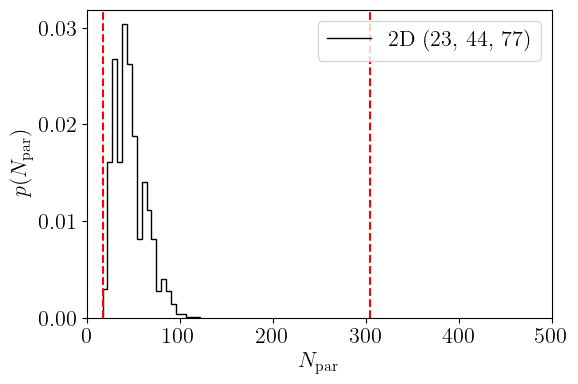

In [10]:
fig, ax = plt.subplots(figsize=(6,4))
ax.set(
    yscale="linear",
    xlabel=r"$N_{\mathrm{par}}$",
    ylabel=r"$p(N_{\mathrm{par}})$",
    xlim=(0, 500),
)

ls = ["-", "--", ":"]

ind=0
ndim=2
offset=2**ndim

n_params = tri_sizes * (ndim + 1) + offset + 1

l, m, h = np.quantile(n_params, [0.05, 0.5, 0.95]).astype(int)

hist, edges = np.histogram(n_params, density=True, bins=20)
ax.stairs(
    hist,
    edges, 
    color='black', 
    ls=ls[ind], 
    label=f"{ndim}D ({l}, {m}, {h})"
)

ax.axvline(nvertices_min * (ndim + 1) + offset + 1, color='r', linestyle='--')
ax.axvline(nvertices_max * (ndim + 1) + offset + 1, color='r', linestyle='--')

ax.legend()
plt.show()
plt.close()

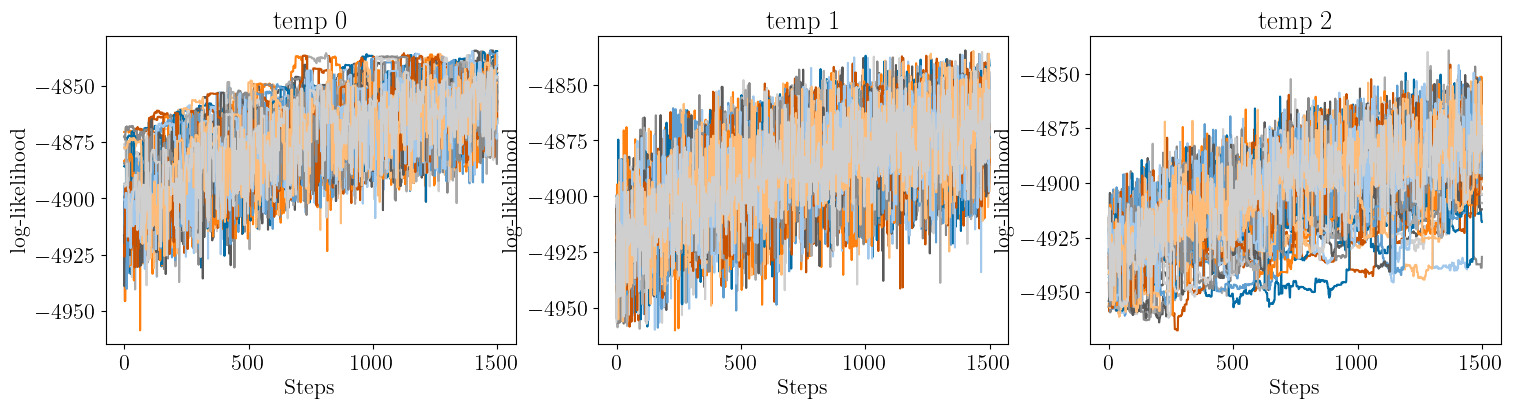

In [11]:
fig, axes = plt.subplots(1, ntemps, figsize=(18,4))
for t,w in product(range(ntemps),range(nwalkers)):
    ax = axes[t]
    ax.plot(back.get_log_like()[:, t, w])
    ax.set(title=f"temp {t}")
    ax.set_xlabel(r"Steps")
    ax.set_ylabel(r"log-likelihood")
plt.show()
plt.close()

In [12]:
nburn = 1_000

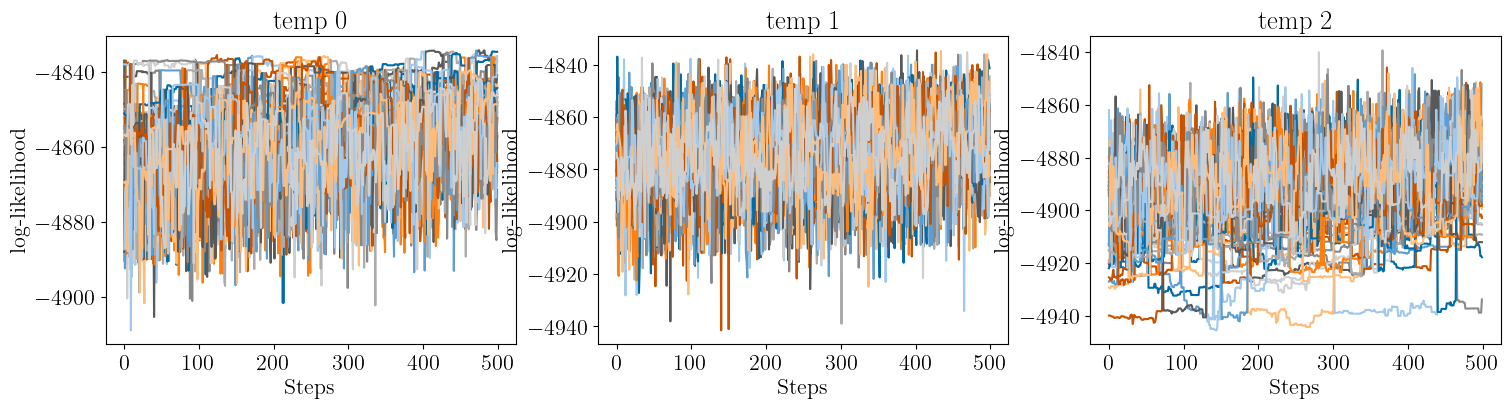

In [13]:
fig, axes = plt.subplots(1, ntemps, figsize=(18,4))
for t,w in product(range(ntemps),range(nwalkers)):
    ax = axes[t]
    ax.plot(back.get_log_like()[nburn:, t, w])
    ax.set(title=f"temp {t}")
    ax.set_xlabel(r"Steps")
    ax.set_ylabel(r"log-likelihood")
plt.show()
plt.close()

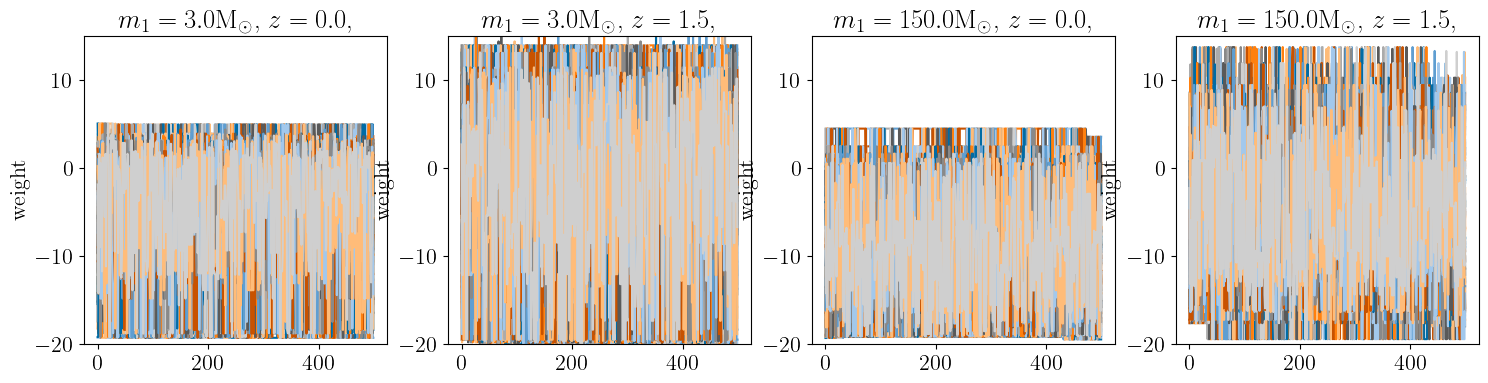

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(18,4))
for n in range(len(corners)):
    ax = axes[n]
    for t,w in product(range(ntemps-1),range(nwalkers)):
        ax.plot(np.ravel(back.chain['corner_w'][nburn:,t,w,0,n]))
    ax.set(title=r"$m_1=%.1f\mathrm{M}_\odot$, $z=%.1f$,"  
            %(corners[n][0],corners[n][1]))
    #ax.set_xlabel(r"Steps")
    ax.set_ylabel(r"weight")
    ax.set_ylim(w_min,w_max)
plt.show()
plt.close()

## Load triangulations

In [15]:
all_triangulations = []
for t in range(ntemps):
    triangulations = [
        back.chain["tri"][step, t, walker][back.inds["tri"][step, t, walker]]
        for step, walker in product(range(nburn,nsteps), range(nwalkers))
    ]
    corner_weights = np.array(
        [
            back.chain["corner_w"][step, t, walker]
            for step, walker in product(range(nburn,nsteps), range(nwalkers))
        ]
    )
    for ind in tqdm(range(len(triangulations))):
        all_triangulations.extend([
            np.vstack([triangulations[ind], np.c_[corners, corner_weights[ind].T]])                
        ])
### KEEP ONLY FIRST TEMPERATURE FOR NOW ###
# t=0
# triangulations = [
#     back.chain["tri"][step, t, walker][back.inds["tri"][step, t, walker]]
#     for step, walker in product(range(nburn,nsteps), range(nwalkers))
# ]
# corner_weights = np.array(
#     [
#         back.chain["corner_w"][step, t, walker]
#         for step, walker in product(range(nburn,nsteps), range(nwalkers))
#     ]
# )
# for ind in tqdm(range(len(triangulations))):
#     all_triangulations.extend([
#         np.vstack([triangulations[ind], np.c_[corners, corner_weights[ind].T]])                
#     ])

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 20000/20000 [00:00<00:00, 214916.72it/s]


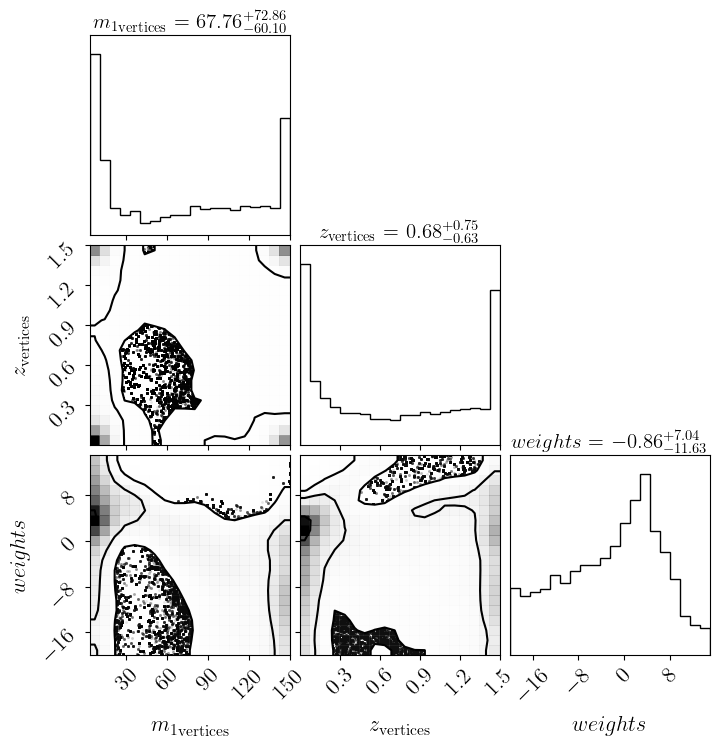

In [16]:
ws = np.hstack([tri[:, -1] for tri in all_triangulations])
vertices = np.vstack([tri[:, :-1] for tri in all_triangulations])    
corner_plot(np.c_[vertices, ws], smooth=True, levels=[0.05, 0.5, 0.95],
            labels=[r"${m_1}_\mathrm{vertices}$", r"$z_\mathrm{vertices}$", r"$weights$"],
            show_titles=True,
            title_kwargs={"fontsize": 15},
           )
plt.show()
plt.close()

In [17]:
betaq_params = []
chi_params = []
tilt_params = []
for t in range(ntemps):
    betaq_params.extend([
        back.chain["beta_q"][step, t, walker][back.inds["beta_q"][step, t, walker]]
        for step, walker in product(range(nburn,nsteps), range(nwalkers))
    ])
    chi_params.extend([
        back.chain["chi"][step, t, walker][back.inds["chi"][step, t, walker]]
        for step, walker in product(range(nburn,nsteps), range(nwalkers))
    ])
    tilt_params.extend([
        back.chain["cos_tilt"][step, t, walker][back.inds["cos_tilt"][step, t, walker]]
        for step, walker in product(range(nburn,nsteps), range(nwalkers))
    ])

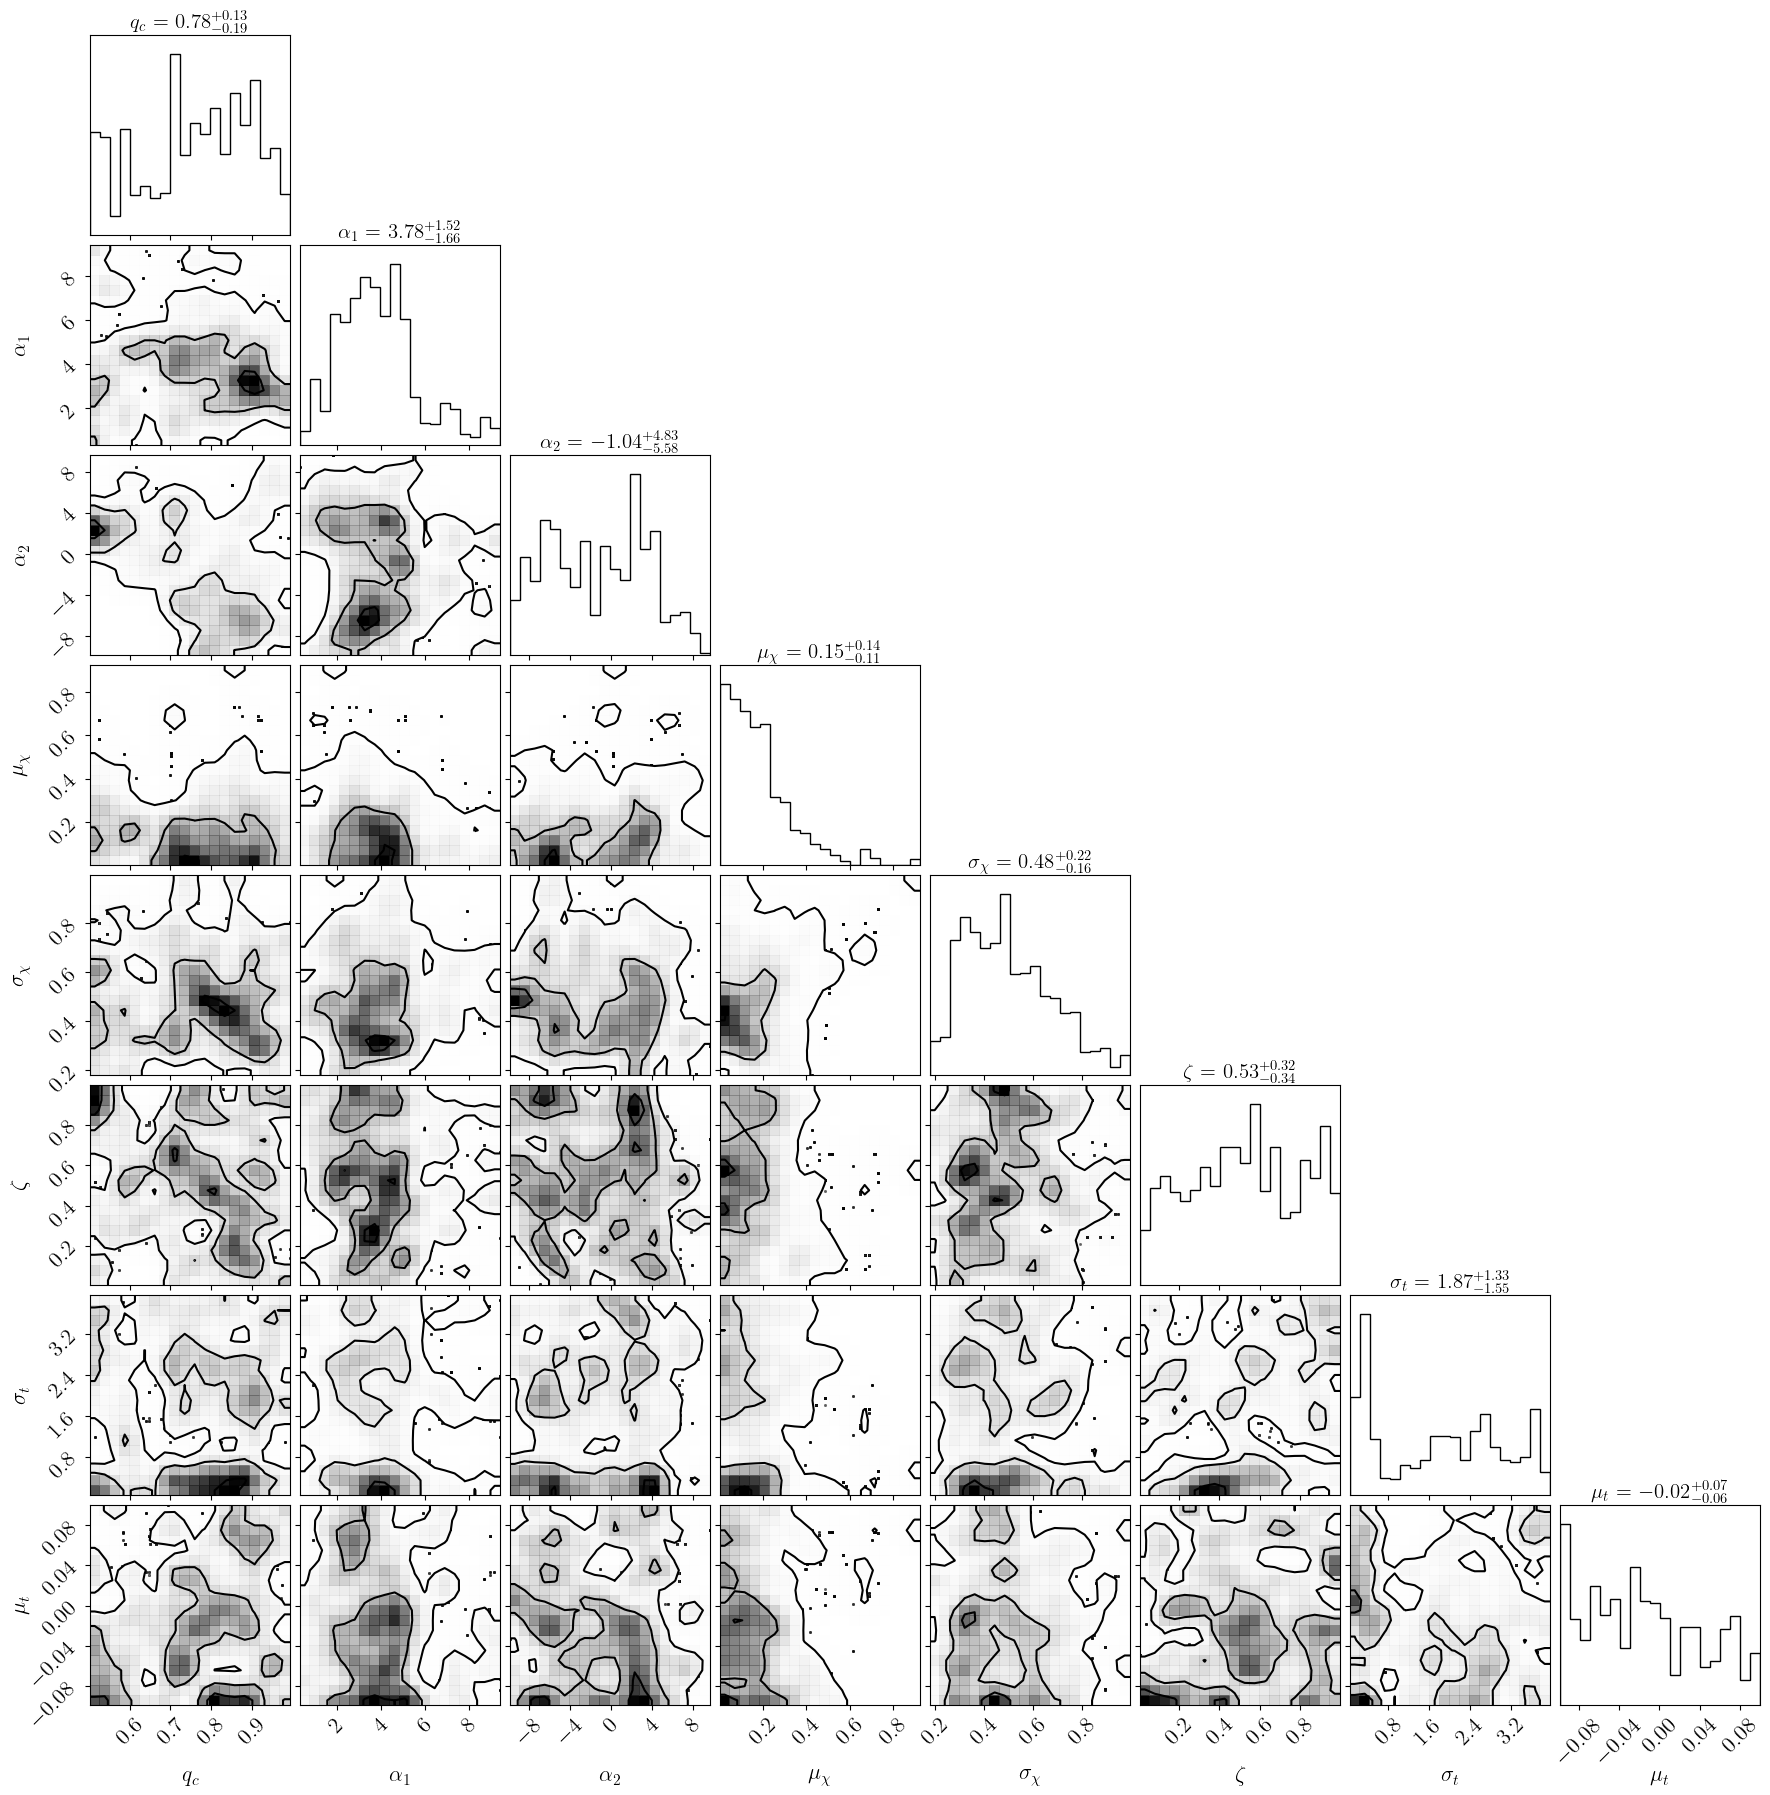

In [18]:
corner_plot(np.c_[np.array(betaq_params)[:,0,:],np.array(chi_params)[:,0,:],np.array(tilt_params)[:,0,:]], 
            smooth=True, levels=[0.05, 0.5, 0.95],
            labels=[r"$q_c$", r"$\alpha_1$", r"$\alpha_2$", r"$\mu_\chi$", r"$\sigma_\chi$", r"$\zeta$", r"$\sigma_t$", r"$\mu_t$"],
            show_titles=True,
            title_kwargs={"fontsize": 15},
           )
plt.show()
plt.close()

In [19]:
## Evolution of the inferred rate at fixed points ##
targets = np.array([[10.,0.5],[35.,0.5],[35.,0.8],[35.,0.8]])
selected_tris = np.random.choice(len(all_triangulations), size=10_000, replace=False)
num_triangulations = len(selected_tris)

log_rate_at_target = np.zeros((num_triangulations,len(targets)))

for ind, tri_ind in enumerate(tqdm(selected_tris)):
    this_delo = delaunaytor.CPUDelaunayInterpolator()
    this_delo.triangulate(all_triangulations[tri_ind])
    log_rate_at_target[ind] = this_delo.interpolate(targets)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 10000/10000 [00:01<00:00, 7498.40it/s]


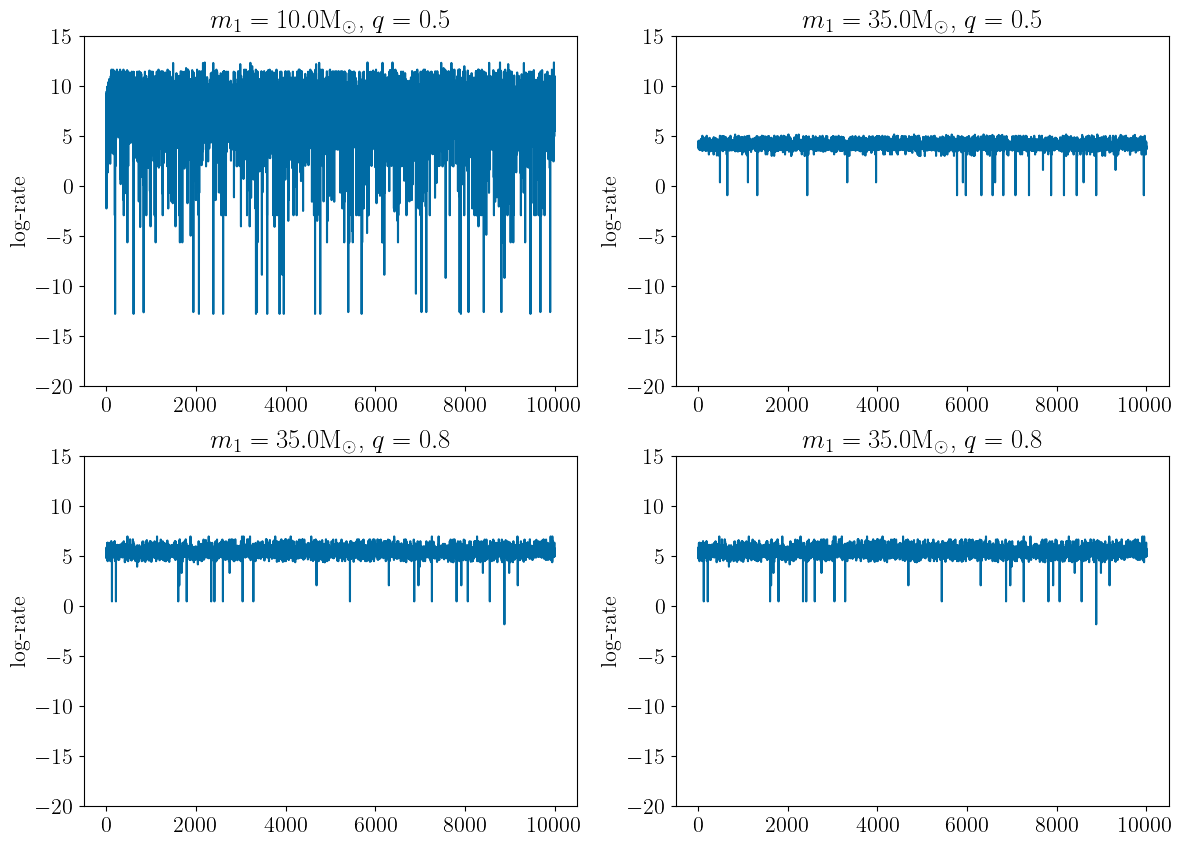

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(14,10))
for n in range(len(targets)):
    ax = axes[n//2, n%2]
    ax.plot(log_rate_at_target[:,n])
    ax.set(title=r"$m_1=%.1f\mathrm{M}_\odot$, $q=%.1f$" 
           %(targets[n][0],targets[n][1]))
    #ax.set_xlabel(r"Steps")
    ax.set_ylabel(r"log-rate")
    ax.set_ylim(w_min,w_max)
plt.show()
plt.close()

### Injections

In [21]:
injections_file = np.load("./gwtc5_injections_full.npz")
detected_injections = np.vstack(
    [injections_file[key + "s"] for key in parameter_keys]
).T
injection_priors = injections_file["inj_priors"]
num_injections = int(injections_file["ninjs"])
Tobs = injections_file['analysis_time'] # in years

In [22]:
print('Total time of the combined runs: %.3f years' %Tobs)
print('Total number of injections for GWTC-3: %.2e' %num_injections)
print('Number of detected injections for GWTC-3: %.2e' %detected_injections.shape[0])

Total time of the combined runs: 3.046 years
Total number of injections for GWTC-3: 1.57e+09
Number of detected injections for GWTC-3: 1.58e+06


## Compute rate over grids

In [23]:
m1_grid = np.linspace(m1_min, m1_max, 148)
z_grid = np.linspace(0.1, z_max, 51)

X, Y = np.meshgrid(m1_grid, z_grid)
grid = np.c_[X.ravel(), Y.ravel()]

dm1 = m1_grid[1] - m1_grid[0]
dz = z_grid[1] - z_grid[0]

In [24]:
log_rate = np.zeros((num_triangulations, grid.shape[0]))

for ind, tri_ind in enumerate(tqdm(selected_tris)):
    this_delo = delaunaytor.CPUDelaunayInterpolator()
    this_delo.triangulate(all_triangulations[tri_ind])
    log_rate[ind] = this_delo.interpolate(grid)
    
log_d2N_dm1dz = log_rate.reshape(num_triangulations, z_grid.shape[0], m1_grid.shape[0])

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 10000/10000 [00:09<00:00, 1110.95it/s]


## Prior

In [25]:
# nsamples_prior = 1_000
# log_rate_prior = np.zeros((nsamples_prior, grid.shape[0]))

# for i in tqdm(range(nsamples_prior)):
#     nleaves_i = np.random.randint(nvertices_min, nvertices_max)
#     tri_i = np.zeros((nleaves_i+offset,ndim+1))
#     tri_i[:offset,:-1] = corners
#     tri_i[offset:,0] = np.random.uniform(m1_min, m1_max, nleaves_i)
#     tri_i[offset:,1] = np.random.uniform(z_min, z_max, nleaves_i)
#     tri_i[offset:,2] = np.random.uniform(q_min, q_max, nleaves_i)
#     tri_i[:,-1] = np.random.uniform(w_min, w_max, nleaves_i+offset)
   
#     this_delo = delaunaytor.CPUDelaunayInterpolator()
#     this_delo.triangulate(tri_i)
#     log_rate_prior[i] = this_delo.interpolate(grid)

# square_rate_prior = log_rate_prior.reshape(nsamples_prior, z_grid.shape[0], m1_grid.shape[0], q_grid.shape[0])

In [26]:
# Nevents_prior = np.sum(np.exp(square_rate_prior) *to_comoving_volume[None,:,None,None], axis=(1,2,3)) *dm1 *dz *dq
# median_prior = np.quantile(Nevents_prior, 0.5)
# low_prior = np.quantile(Nevents_prior, 0.05)
# high_prior = np.quantile(Nevents_prior, 0.95)

# Marginals

In [27]:
zeval = 0.2
zeval_ind = np.argmin(np.abs(z_grid-zeval))

toRate_at_zeval = (1 + zeval) / (
        4 * np.pi * Tobs * Planck15.differential_comoving_volume(zeval).to(u.Gpc**3 / u.sr).value
    )

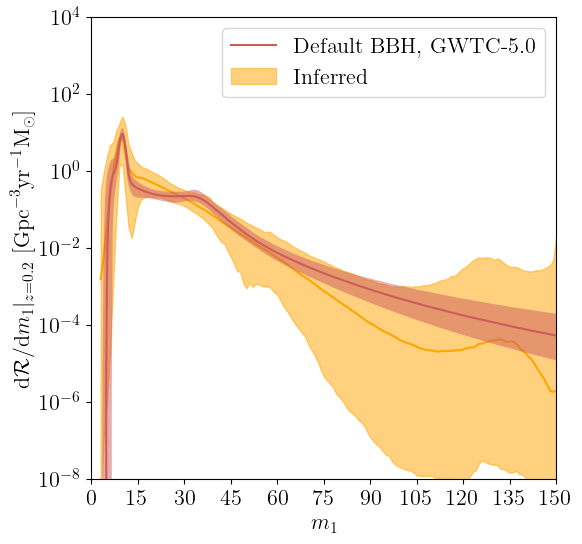

In [28]:
fig, ax = plt.subplots(1, 1, figsize=(6,6))

redshift_factor_strong_bbh_o4b = (1 + zeval)**(strong_bbh_O4b.get_hyperparameter_samples(hyperparameters=['lamb']))
redshift_factor_pixelpop_q = (1 + zeval)**(m1q_pixelpop.get_hyperparameter_samples(hyperparameters=['lamb']))
ax.plot(strong_bbh_O4b_m1_grid, np.quantile(redshift_factor_strong_bbh_o4b * strong_bbh_O4b_Rm1, 0.5, axis=0),
        color=spm_color, label='Default BBH, GWTC-5.0', lw=1.5, zorder=5)
ax.fill_between(strong_bbh_O4b_m1_grid,
        np.quantile(redshift_factor_strong_bbh_o4b * strong_bbh_O4b_Rm1, 0.05, axis=0),
        np.quantile(redshift_factor_strong_bbh_o4b * strong_bbh_O4b_Rm1, 0.95, axis=0),
        color=spm_color, edgecolor=None, alpha=0.5, zorder=5)
# ax.step(np.exp(pixelpop_m1_grid), np.quantile(redshift_factor_pixelpop_m1 * pixelpop_Rm1 /np.exp(pixelpop_m1_grid) , 0.5, axis = 0),
#         color=wpm_color, label='PixelPop, GWTC-5.0', lw=2.0, zorder=2)
# ax.fill_between(np.exp(pixelpop_m1_grid),
#         np.quantile(redshift_factor_pixelpop_m1 * pixelpop_Rm1 / np.exp(pixelpop_m1_grid) , 0.05, axis = 0),
#         np.quantile(redshift_factor_pixelpop_m1 * pixelpop_Rm1 / np.exp(pixelpop_m1_grid), 0.95, axis = 0),
#         color=wpm_color, edgecolor=None, alpha=0.4, step='pre', zorder=2)

dRdm1_zeval = np.exp(log_d2N_dm1dz)[:,zeval_ind,:] *toRate_at_zeval
low_dRdm1 = np.quantile(dRdm1_zeval, 0.05, axis=0)
median_dRdm1 = np.quantile(dRdm1_zeval, 0.5, axis=0)
high_dRdm1 = np.quantile(dRdm1_zeval, 0.95, axis=0)

ax.plot(m1_grid, median_dRdm1, color="orange")
ax.fill_between(m1_grid, low_dRdm1, high_dRdm1,
                color="orange", alpha=0.5,
                label=r'Inferred',
                )

# dRdm1_prior_zeval = np.sum(np.exp(square_rate_prior[:,zeval_ind,:,:]) 
#                            *to_comoving_volume[zeval_ind], axis=2) *dq
# low_dRdm1_prior = np.quantile(dRdm1_prior_zeval, 0.05, axis=0)
# median_dRdm1_prior = np.quantile(dRdm1_prior_zeval, 0.5, axis=0)
# high_dRdm1_prior = np.quantile(dRdm1_prior_zeval, 0.95, axis=0)
# ax.plot(m1_grid, median_dRdm1_prior, color="forestgreen", alpha=0.5)
# ax.fill_between(m1_grid, low_dRdm1_prior, high_dRdm1_prior,
#                 color="forestgreen", alpha=0.25,
#                 label='Induced prior',
#                 )

ax.set_xlabel(r'$m_1$')
ax.set_xlim(xmin=m1_min, xmax=m1_max)
ax.set_xticks(np.linspace(0,m1_max,int(m1_max/15)+1))
ax.set_ylabel(r'$\mathrm{d}\mathcal{R}/\mathrm{d}m_1 |_{z=%.1f}\ [\mathrm{Gpc}^{-3}\mathrm{yr}^{-1}\mathrm{M}_\odot]$' %zeval)
ax.set_yscale('log')
#ax.set_box_aspect(1)
ax.set_ylim(ymin=1e-8, ymax=1e4)
ax.legend(loc='best')

plt.savefig('m1_z/m1_from2D_m1z.png', dpi=1200, bbox_inches='tight')
plt.show()
plt.close()

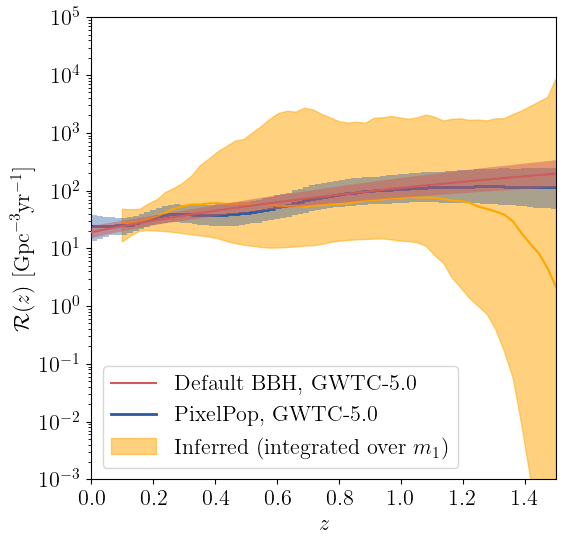

In [29]:
fig, ax = plt.subplots(1, 1, figsize=(6,6))

ax.plot(strong_bbh_O4b_z_grid, np.quantile(strong_bbh_O4b_Rz, 0.5, axis = 0),
        color=spm_color, label='Default BBH, GWTC-5.0', lw=1.5, zorder=5)
ax.fill_between(strong_bbh_O4b_z_grid,
        np.quantile(strong_bbh_O4b_Rz, 0.05, axis=0),
        np.quantile(strong_bbh_O4b_Rz, 0.95, axis=0),
        color=spm_color, edgecolor=None, alpha=0.5, zorder=5)
ax.step(pixelpop_z_grid, np.quantile(pixelpop_Rz , 0.5, axis = 0),
        color=wpm_color, label='PixelPop, GWTC-5.0', lw=2.0, zorder=2)
ax.fill_between(pixelpop_z_grid,
        np.quantile(pixelpop_Rz, 0.05, axis = 0),
        np.quantile(pixelpop_Rz, 0.95, axis = 0),
        color=wpm_color, edgecolor=None, alpha=0.4, step='pre', zorder=2)

toRate = (1 + z_grid) / (
        4 * np.pi * Tobs * Planck15.differential_comoving_volume(z_grid).to(u.Gpc**3 / u.sr).value
    )
Rz = np.sum(np.exp(log_d2N_dm1dz),axis=2) *toRate
low_Rz = np.quantile(Rz, 0.05, axis=0)
median_Rz = np.quantile(Rz, 0.5, axis=0)
high_Rz = np.quantile(Rz, 0.95, axis=0)

ax.plot(z_grid, median_Rz, color="orange")
ax.fill_between(z_grid, low_Rz, high_Rz,
                color="orange", alpha=0.5,
                label=r'Inferred (integrated over $m_1$)',
                )

# Rz_prior = np.sum(np.exp(square_rate_prior) 
#                     *to_comoving_volume[None,:,None,None], axis=(2,3)) *dq *dm1
# low_Rz_prior = np.quantile(Rz_prior, 0.05, axis=0)
# median_Rz_prior = np.quantile(Rz_prior, 0.5, axis=0)
# high_Rz_prior = np.quantile(Rz_prior, 0.95, axis=0)
# ax.plot(z_grid, median_Rz_prior, color="forestgreen", alpha=0.5)
# ax.fill_between(z_grid, low_Rz_prior, high_Rz_prior,
#                 color="forestgreen", alpha=0.25,
#                 label='Induced prior',
#                 )


ax.set_xlabel(r'$z$')
ax.set_xlim(xmin=0, xmax=z_max)
ax.set_xticks(np.linspace(0,z_max,int(z_max*10)+1)[::2])
ax.set_ylabel(r'$\mathcal{R}(z)\ [\mathrm{Gpc}^{-3}\mathrm{yr}^{-1}]$')
ax.set_yscale('log')
ax.legend(loc='best')
#ax.set_box_aspect(1)
ax.set_ylim(ymin=1e-3, ymax=1e5)

plt.show()
plt.close()

# 95% - 5% CI 

In [30]:
linestyles = ['solid', 'dashed', 'dotted', 'dashdot', (0, (5, 5))]  # You can add more or customize
n_contours = min(5, len(linestyles))

cmap = plt.get_cmap('viridis')
norm = mpl.colors.Normalize(vmin=-15, vmax=3)

In [31]:
log_cosmo_rate = log_d2N_dm1dz + np.log(toRate)[None,:,None]
median = np.quantile(log_cosmo_rate, 0.5, axis=0)
low = np.quantile(log_cosmo_rate, 0.05, axis=0)
high = np.quantile(log_cosmo_rate, 0.95, axis=0)

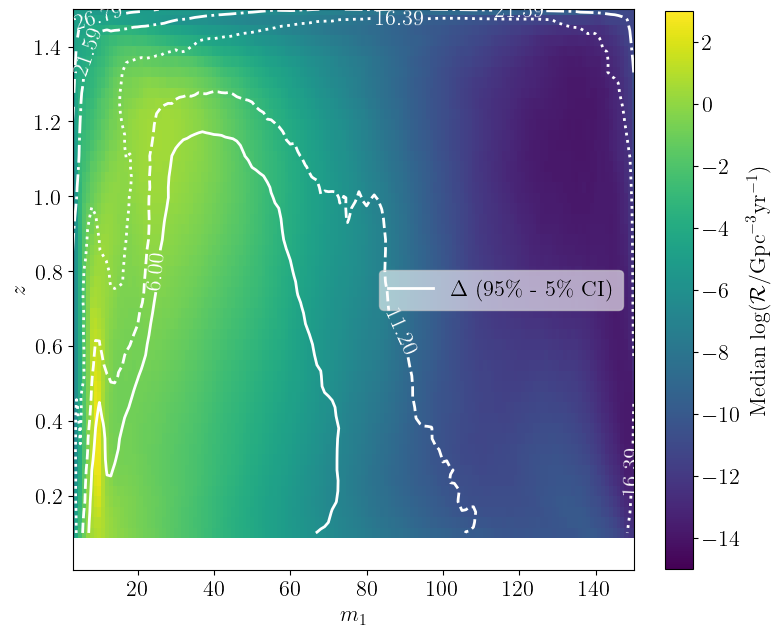

In [32]:

fig, ax = plt.subplots(figsize=(8,8))

c = ax.pcolormesh(m1_grid, z_grid, median,
                  cmap=cmap, norm=norm,
                 )


# Calculate the difference
diff = high - low

# Define contour levels (choose appropriate values for your data)
levels = np.linspace(np.nanmin(diff), np.nanmax(diff), n_contours + 2)[1:-1]  # avoid min/max

# Plot contours with different linestyles
contours = ax.contour(
    m1_grid, z_grid, diff, 
    levels=levels, 
    linestyles=linestyles[:n_contours],
    linewidths=2, 
    colors='white'
)
ax.clabel(contours, fmt="%.2f")
ax.plot([],[], c='white', lw=2, label=r'$\Delta$' +r' (95\% - 5\% CI)')

# ax.scatter(event_barycenters[:,0], event_barycenters[:,2],
#            c='r', marker='*', s=4**2, zorder=2,
#            label='GW events',
#           )

# injections_at_z = np.abs(detected_injections[:,1]-zeval) /zeval < 0.001
# ax.scatter(detected_injections[injections_at_z,0], detected_injections[injections_at_z,2],
#            c='r', marker='d', s=4**2, zorder=1,
#            label='Detected injections',
#           )
ax.set_xlabel('$m_1$')
ax.set_xlim(m1_min,m1_max)
ax.set_ylabel('$z$')
ax.set_ylim(z_min,z_max)
ax.legend(loc='center right', framealpha=0.6)
ax.set_box_aspect(1)

cbar = fig.colorbar(c, ax=ax, fraction=0.045)
cbar.set_label(r'Median log($\mathcal{R}/\mathrm{Gpc}^{-3}\mathrm{yr}^{-1})$')

plt.savefig('m1_z/m1_z_from2D_m1z.png', dpi=1200, bbox_inches='tight')
plt.show()
plt.close()

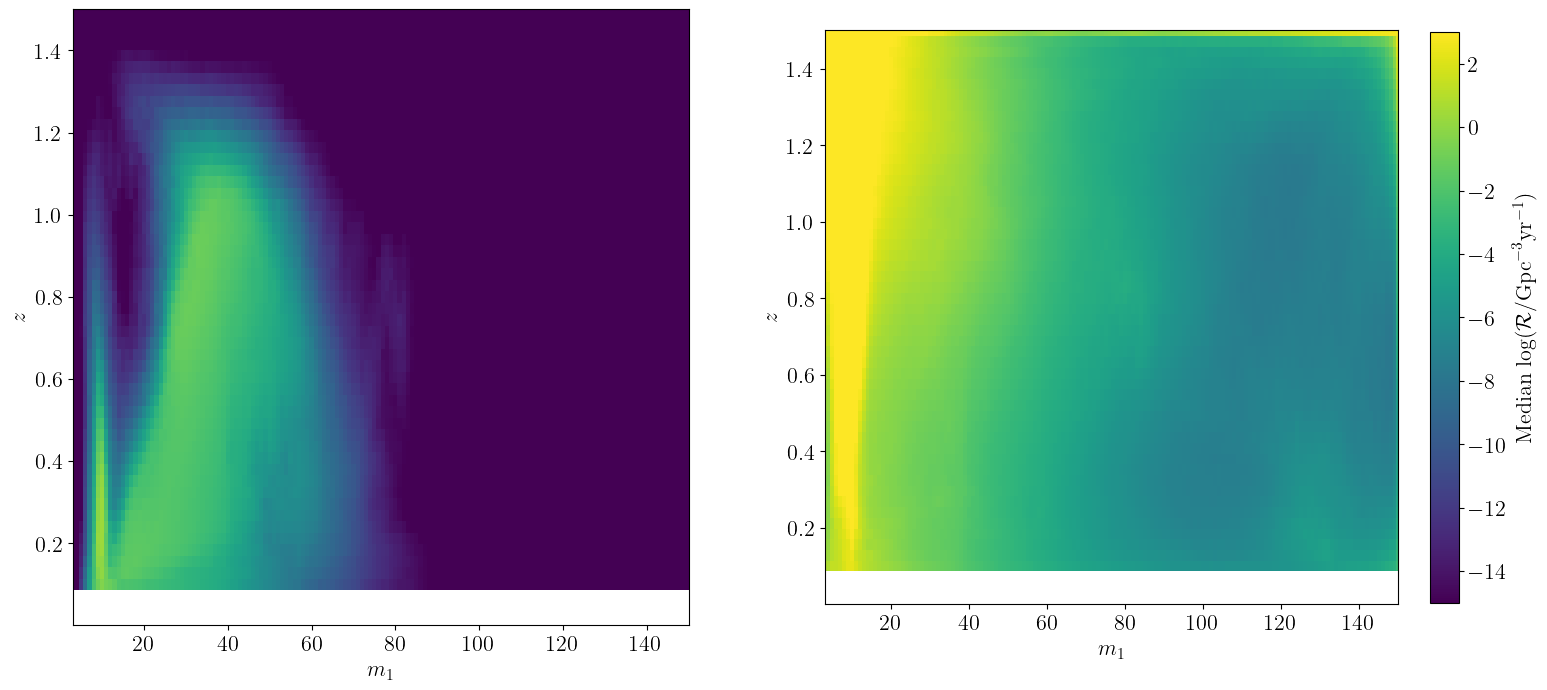

In [33]:

fig, axes = plt.subplots(1, 2, figsize=(18,8))

c = axes[0].pcolormesh(m1_grid, z_grid, low,
                  cmap=cmap, norm=norm,
                 )

c = axes[1].pcolormesh(m1_grid, z_grid, high,
                  cmap=cmap, norm=norm,
                 )
for ax in axes:
    ax.set_xlabel('$m_1$')
    ax.set_xlim(m1_min,m1_max)
    ax.set_ylabel('$z$')
    ax.set_ylim(z_min,z_max)
    #ax.legend(loc='center right', framealpha=0.6)
    ax.set_box_aspect(1)

cbar = fig.colorbar(c, ax=axes[1], fraction=0.045)
cbar.set_label(r'Median log($\mathcal{R}/\mathrm{Gpc}^{-3}\mathrm{yr}^{-1})$')

plt.show()
plt.close()